# Amazon Bestselling Books Classification Using Logistic Regression

## Programming for Data Analytics 2

### Part 2: Classification with Logistic Regression from Scratch

This project develops a binary classification model using Logistic Regression implemented from scratch in Python.

The objective is to analyse Amazon bestselling books and develop a model that predicts whether a book has **high bestseller potential** based on selected characteristics such as user rating, price, publication year and genre.

The analysis includes:

- Exploratory Data Analysis (EDA)
- Data cleaning
- Feature selection
- Data preparation
- Logistic Regression implemented from scratch
- Model training
- Model evaluation
- Hyperparameter experimentation
- Interpretation of results
- Discussion of limitations

## 1. Project Objective

The main objective of this project is to develop a Logistic Regression classification model from scratch to classify books according to their bestseller potential.

The analysis will investigate whether characteristics of books, including:

- User rating
- Price
- Publication year
- Genre

can be used to distinguish books with relatively high levels of reader engagement from books with lower levels of engagement within the dataset.

The project will follow a complete machine-learning workflow consisting of data exploration, cleaning, feature selection, model development, evaluation and interpretation.

## 2. Dataset Evaluation and Justification

The dataset used in this project is the Amazon Top 50 Bestselling Books dataset.

The dataset contains information about books appearing among Amazon's top bestselling books between 2009 and 2019.

The main variables include:

- **Name** – the title of the book
- **Author** – the author of the book
- **User Rating** – the average user rating
- **Reviews** – the number of reviews received
- **Price** – the listed price of the book
- **Year** – the year associated with the bestseller listing
- **Genre** – Fiction or Non Fiction

The dataset is suitable for this analysis because it contains numerical and categorical variables that can be investigated as potential predictors.

However, an important limitation must be recognised. The dataset contains books that were already identified as bestselling books. Therefore, it does not contain a natural group of non-bestselling books.

For this reason, the classification target will be constructed from the review distribution. Books with review counts at or above the 75th percentile will be classified as having **High Bestseller Potential**, while the remaining books will be classified as having **Lower Bestseller Potential**.

This target definition allows a binary classification problem to be developed while clearly acknowledging that the model is not predicting an official Amazon bestseller status.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:

file_path = r"C:\Users\baloy\Documents\Dataset Topselling\bestsellers with categories.csv"

books = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Dataset shape:", books.shape)

Dataset loaded successfully.
Dataset shape: (550, 7)


In [5]:
# Display the first five records

books.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [6]:
# Display the last five records

books.tail()

,Name,Author,User Rating,Reviews,Price,Year,Genre
545,Wrecking Ball (Diary of a Wimpy Kid Book 14),Jeff Kinney,4.9,9413,8,2019,Fiction
546,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2016,Non Fiction
547,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2017,Non Fiction
548,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2018,Non Fiction
549,You Are a Badass: How to Stop Doubting Your Gr...,Jen Sincero,4.7,14331,8,2019,Non Fiction


## 3. Understanding the Dataset

Before developing the classification model, it is important to understand the structure and quality of the data.

The following checks will be performed:

- Number of observations
- Number of variables
- Data types
- Missing values
- Duplicate records
- Descriptive statistics
- Unique values in categorical variables

This is important because poor-quality data can negatively affect machine-learning model performance.

In [7]:
# ============================================
# DATASET INFORMATION
# ============================================

books.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         550 non-null    object 
 1   Author       550 non-null    object 
 2   User Rating  550 non-null    float64
 3   Reviews      550 non-null    int64  
 4   Price        550 non-null    int64  
 5   Year         550 non-null    int64  
 6   Genre        550 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 30.2+ KB


In [8]:
# ============================================
# COLUMN NAMES
# ============================================

print("Dataset columns:")
print(books.columns.tolist())

Dataset columns:
['Name', 'Author', 'User Rating', 'Reviews', 'Price', 'Year', 'Genre']


In [9]:
# ============================================
# DATASET DIMENSIONS
# ============================================

rows, columns = books.shape

print("Number of rows:", rows)
print("Number of columns:", columns)

Number of rows: 550
Number of columns: 7


In [10]:
# ============================================
# MISSING VALUES
# ============================================

missing_values = books.isnull().sum()

print("Missing values per column:")
print(missing_values)

Missing values per column:
Name           0
Author         0
User Rating    0
Reviews        0
Price          0
Year           0
Genre          0
dtype: int64


In [11]:
# ============================================
# DUPLICATE RECORDS
# ============================================

duplicates = books.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [12]:
# ============================================
# DESCRIPTIVE STATISTICS
# ============================================

books.describe()

,User Rating,Reviews,Price,Year
count,550.000000,550.000000,550.000000,550.000000
mean,4.618364,11953.281818,13.100000,2014.000000
std,0.226980,11731.132017,10.842262,3.165156
min,3.300000,37.000000,0.000000,2009.000000
25%,4.500000,4058.000000,7.000000,2011.000000
50%,4.700000,8580.000000,11.000000,2014.000000
75%,4.800000,17253.250000,16.000000,2017.000000
max,4.900000,87841.000000,105.000000,2019.000000


In [13]:
# ============================================
# UNIQUE VALUES
# ============================================

for column in books.columns:
    print("\n", column)
    print(books[column].nunique(), "unique values")


 Name
351 unique values

 Author
248 unique values

 User Rating
14 unique values

 Reviews
346 unique values

 Price
40 unique values

 Year
11 unique values

 Genre
2 unique values


## 4. Data Cleaning

Data cleaning is performed before modelling to ensure that the dataset is consistent and suitable for analysis.

The following cleaning procedures will be considered:

1. Standardising column names
2. Removing duplicate observations
3. Checking missing values
4. Checking for impossible numerical values
5. Checking categorical values
6. Checking the data types of variables

The original dataset will be preserved conceptually while a cleaned copy is used for modelling.

In [14]:
# ============================================
# CREATE A COPY FOR CLEANING
# ============================================

books_clean = books.copy()

# Standardise column names
books_clean.columns = (
    books_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(books_clean.columns.tolist())

['name', 'author', 'user_rating', 'reviews', 'price', 'year', 'genre']


In [15]:
# ============================================
# REMOVE DUPLICATES
# ============================================

before = len(books_clean)

books_clean = books_clean.drop_duplicates()

after = len(books_clean)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicates removed:", before - after)

Rows before removing duplicates: 550
Rows after removing duplicates: 550
Duplicates removed: 0


In [16]:
# ============================================
# CHECK MISSING VALUES AFTER CLEANING
# ============================================

print(books_clean.isnull().sum())

name           0
author         0
user_rating    0
reviews        0
price          0
year           0
genre          0
dtype: int64


In [17]:
# ============================================
# CHECK NUMERICAL VARIABLES
# ============================================

numeric_columns = [
    "user_rating",
    "reviews",
    "price",
    "year"
]

books_clean[numeric_columns].describe()

,user_rating,reviews,price,year
count,550.000000,550.000000,550.000000,550.000000
mean,4.618364,11953.281818,13.100000,2014.000000
std,0.226980,11731.132017,10.842262,3.165156
min,3.300000,37.000000,0.000000,2009.000000
25%,4.500000,4058.000000,7.000000,2011.000000
50%,4.700000,8580.000000,11.000000,2014.000000
75%,4.800000,17253.250000,16.000000,2017.000000
max,4.900000,87841.000000,105.000000,2019.000000


In [18]:
# ============================================
# CHECK FOR IMPOSSIBLE VALUES
# ============================================

print("Minimum user rating:", books_clean["user_rating"].min())
print("Maximum user rating:", books_clean["user_rating"].max())

print("Minimum reviews:", books_clean["reviews"].min())
print("Minimum price:", books_clean["price"].min())

print("Minimum year:", books_clean["year"].min())
print("Maximum year:", books_clean["year"].max())

Minimum user rating: 3.3
Maximum user rating: 4.9
Minimum reviews: 37
Minimum price: 0
Minimum year: 2009
Maximum year: 2019


In [19]:
# ============================================
# CHECK GENRE VALUES
# ============================================

print(books_clean["genre"].value_counts())

genre
Non Fiction    310
Fiction        240
Name: count, dtype: int64


## 5. Exploratory Data Analysis

Exploratory Data Analysis is performed to identify patterns, distributions and relationships within the dataset.

The analysis will investigate:

- Distribution of user ratings
- Distribution of book prices
- Distribution of reviews
- Distribution of publication years
- Fiction versus Non Fiction books
- Relationship between reviews and ratings
- Relationship between price and reviews
- Review distributions across genres

EDA is important because it provides evidence for feature selection and helps identify potential data-quality issues before modelling.

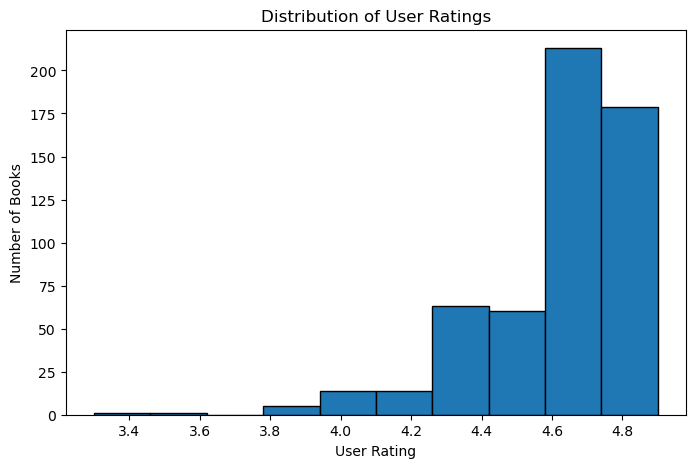

In [20]:
# ============================================
# USER RATING DISTRIBUTION
# ============================================

plt.figure(figsize=(8, 5))

plt.hist(
    books_clean["user_rating"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of User Ratings")
plt.xlabel("User Rating")
plt.ylabel("Number of Books")
plt.show()

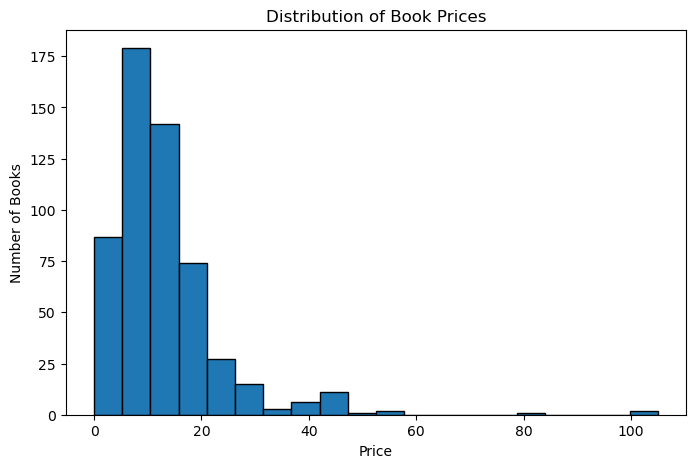

In [21]:
# ============================================
# BOOK PRICE DISTRIBUTION
# ============================================

plt.figure(figsize=(8, 5))

plt.hist(
    books_clean["price"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Book Prices")
plt.xlabel("Price")
plt.ylabel("Number of Books")
plt.show()

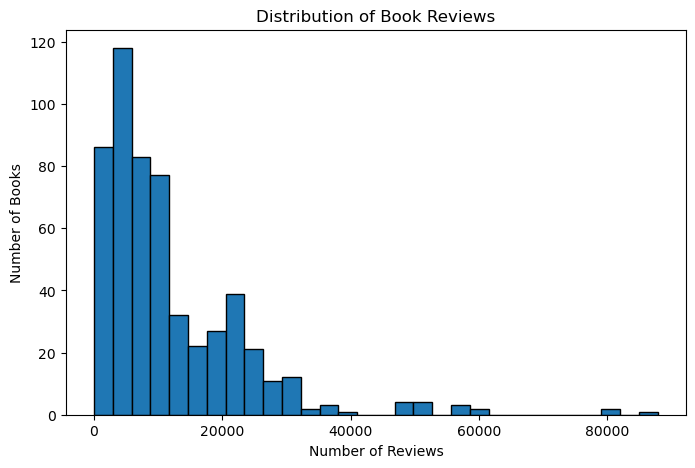

In [22]:
# ============================================
# REVIEWS DISTRIBUTION
# ============================================

plt.figure(figsize=(8, 5))

plt.hist(
    books_clean["reviews"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Book Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Number of Books")
plt.show()

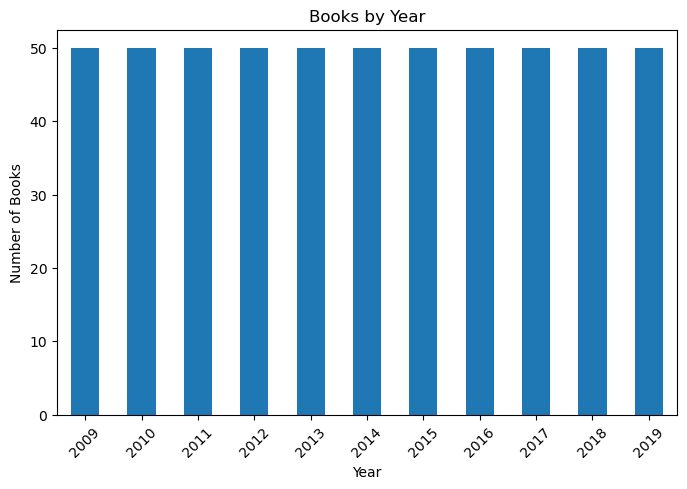

In [23]:
# ============================================
# PUBLICATION YEAR DISTRIBUTION
# ============================================

plt.figure(figsize=(8, 5))

books_clean["year"].value_counts().sort_index().plot(kind="bar")

plt.title("Books by Year")
plt.xlabel("Year")
plt.ylabel("Number of Books")
plt.xticks(rotation=45)

plt.show()

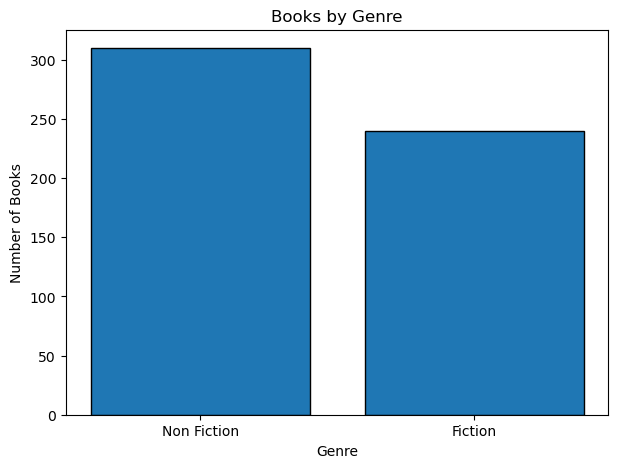

In [24]:
# ============================================
# GENRE DISTRIBUTION
# ============================================

genre_counts = books_clean["genre"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    genre_counts.index,
    genre_counts.values,
    edgecolor="black"
)

plt.title("Books by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Books")

plt.show()

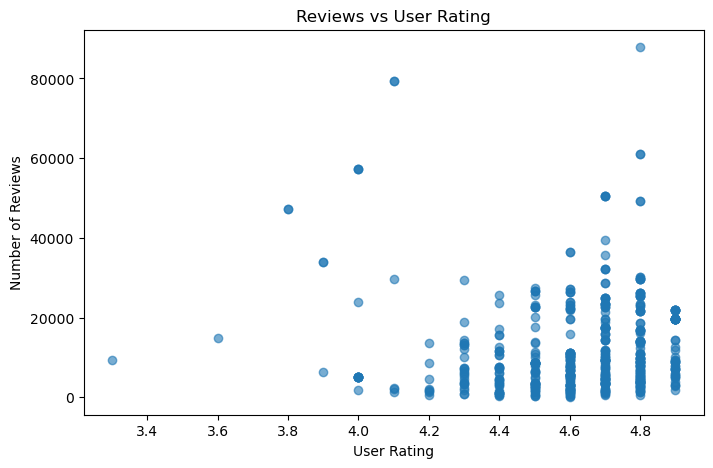

In [25]:
# ============================================
# REVIEWS VS USER RATING
# ============================================

plt.figure(figsize=(8, 5))

plt.scatter(
    books_clean["user_rating"],
    books_clean["reviews"],
    alpha=0.6
)

plt.title("Reviews vs User Rating")
plt.xlabel("User Rating")
plt.ylabel("Number of Reviews")

plt.show()

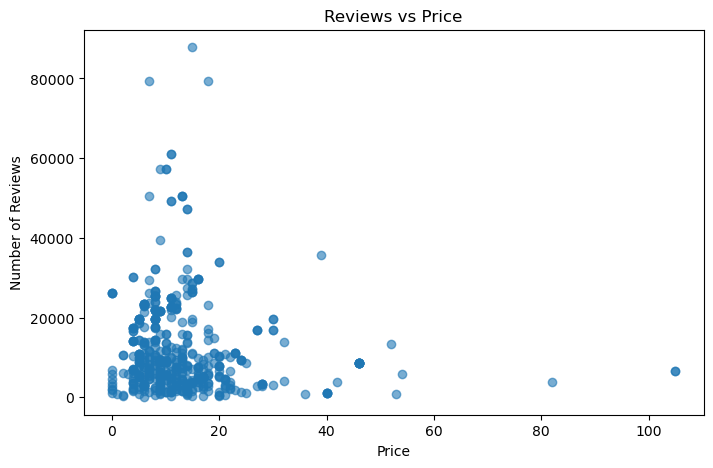

In [26]:
# ============================================
# REVIEWS VS PRICE
# ============================================

plt.figure(figsize=(8, 5))

plt.scatter(
    books_clean["price"],
    books_clean["reviews"],
    alpha=0.6
)

plt.title("Reviews vs Price")
plt.xlabel("Price")
plt.ylabel("Number of Reviews")

plt.show()

genre
Fiction        15683.791667
Non Fiction     9065.145161
Name: reviews, dtype: float64


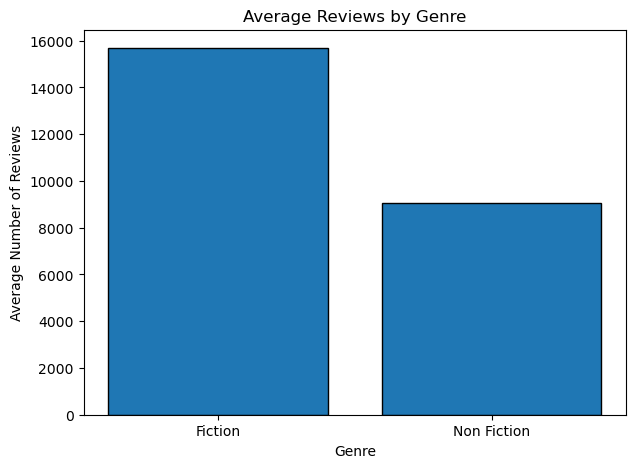

In [27]:
# ============================================
# AVERAGE REVIEWS BY GENRE
# ============================================

average_reviews = books_clean.groupby("genre")["reviews"].mean()

print(average_reviews)

plt.figure(figsize=(7, 5))

plt.bar(
    average_reviews.index,
    average_reviews.values,
    edgecolor="black"
)

plt.title("Average Reviews by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Number of Reviews")

plt.show()

## 6. Creating the Classification Target

The original dataset does not contain a binary variable indicating whether a book is a bestseller or not because all observations originate from an Amazon bestseller list.

Therefore, a classification target must be constructed.

The 75th percentile of the number of reviews will be used as the threshold.

Books with review counts greater than or equal to this threshold will receive:

**1 = High Bestseller Potential**

Books below the threshold will receive:

**0 = Lower Bestseller Potential**

This approach creates a binary classification problem while avoiding the incorrect claim that the dataset contains actual non-bestseller books.

In [28]:
# ============================================
# CREATE TARGET VARIABLE
# ============================================

review_threshold = books_clean["reviews"].quantile(0.75)

print("75th percentile review threshold:", review_threshold)

books_clean["bestseller"] = (
    books_clean["reviews"] >= review_threshold
).astype(int)

books_clean["bestseller"].value_counts()

75th percentile review threshold: 17253.25


bestseller
0    412
1    138
Name: count, dtype: int64

Target distribution:
bestseller
0    412
1    138
Name: count, dtype: int64


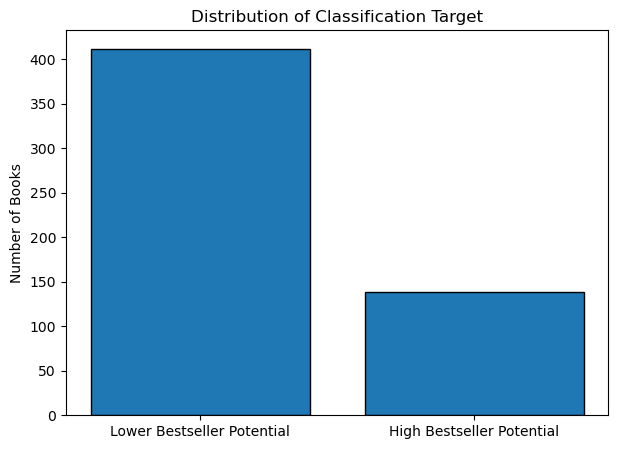

In [29]:
# ============================================
# TARGET DISTRIBUTION
# ============================================

target_counts = books_clean["bestseller"].value_counts().sort_index()

print("Target distribution:")
print(target_counts)

plt.figure(figsize=(7, 5))

plt.bar(
    ["Lower Bestseller Potential", "High Bestseller Potential"],
    target_counts.values,
    edgecolor="black"
)

plt.title("Distribution of Classification Target")
plt.ylabel("Number of Books")

plt.show()

## 7. Avoiding Data Leakage

The `reviews` variable was used to construct the target variable.

Therefore, `reviews` will not be used as a predictor in the Logistic Regression model.

Including `reviews` as an input feature would result in data leakage because the model would receive direct information about how the target variable was created.

The predictor variables selected for the initial model are:

- User Rating
- Price
- Year
- Genre

These variables provide information about the characteristics of the books without directly defining the classification target.

## 8. Feature Selection

Feature selection is an important stage of the modelling process.

The selected predictors are:

### Numerical features

- `user_rating`
- `price`
- `year`

### Categorical feature

- `genre`

The `genre` variable will be converted into a numerical representation using one-hot encoding.

The `reviews` variable is deliberately excluded because it was used to construct the target variable.

In [30]:
# ============================================
# SELECT FEATURES
# ============================================

X = books_clean[
    [
        "user_rating",
        "price",
        "year",
        "genre"
    ]
].copy()

y = books_clean["bestseller"].copy()

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   user_rating  price  year        genre
0          4.7      8  2016  Non Fiction
1          4.6     22  2011      Fiction
2          4.7     15  2018  Non Fiction
3          4.7      6  2017      Fiction
4          4.8     12  2019  Non Fiction

Target:
0    1
1    0
2    1
3    1
4    0
Name: bestseller, dtype: int64


In [31]:
# ============================================
# ENCODE GENRE
# ============================================

X = pd.get_dummies(
    X,
    columns=["genre"],
    drop_first=True,
    dtype=int
)

print("Encoded features:")
print(X.head())

print("\nFeature names:")
print(X.columns.tolist())

Encoded features:
   user_rating  price  year  genre_Non Fiction
0          4.7      8  2016                  1
1          4.6     22  2011                  0
2          4.7     15  2018                  1
3          4.7      6  2017                  0
4          4.8     12  2019                  1

Feature names:
['user_rating', 'price', 'year', 'genre_Non Fiction']


## 9. Train-Test Split

The dataset will be divided into training and testing sets.

An 80/20 split will be used:

- 80% of the observations will be used for training.
- 20% will be used for testing.

A stratified split is used to maintain a similar proportion of the two target classes in both datasets.

A fixed random state is also used to make the results reproducible.

In [32]:
# ============================================
# TRAIN-TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

Training observations: 440
Testing observations: 110


## 10. Feature Scaling

Logistic Regression uses numerical optimisation to estimate model parameters.

The numerical features have different scales. For example, price and year have very different numerical ranges.

Standardisation will therefore be applied using:

\[
z = \frac{x-\mu}{\sigma}
\]

where:

- \(x\) is the original value
- \(\mu\) is the mean
- \(\sigma\) is the standard deviation

The scaler is fitted only on the training data to prevent information from the testing set from influencing the model.

In [33]:
# ============================================
# STANDARDISE FEATURES
# ============================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled successfully.")
print("Testing data scaled successfully.")

Training data scaled successfully.
Testing data scaled successfully.


# 11. Logistic Regression From Scratch

Logistic Regression is a supervised classification algorithm used to predict the probability of a binary outcome.

The logistic function, also known as the sigmoid function, is:

\[
\sigma(z)=\frac{1}{1+e^{-z}}
\]

The output is between 0 and 1 and can therefore be interpreted as a probability.

The model will classify an observation as:

- Class 1 if probability ≥ 0.5
- Class 0 if probability < 0.5

The model will be implemented manually rather than using a pre-built Logistic Regression estimator.

In [34]:
# ============================================
# LOGISTIC REGRESSION FROM SCRATCH
# ============================================

class LogisticRegressionScratch:

    def __init__(
        self,
        learning_rate=0.01,
        iterations=10000
    ):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    # Sigmoid function
    def sigmoid(self, z):

        # Prevent numerical overflow
        z = np.clip(z, -500, 500)

        return 1 / (1 + np.exp(-z))

    # Binary cross-entropy loss
    def compute_loss(self, y, probabilities):

        epsilon = 1e-15

        probabilities = np.clip(
            probabilities,
            epsilon,
            1 - epsilon
        )

        loss = -np.mean(
            y * np.log(probabilities)
            +
            (1 - y) * np.log(1 - probabilities)
        )

        return loss

    # Train model
    def fit(self, X, y):

        n_samples, n_features = X.shape

        # Initialise parameters
        self.weights = np.zeros(n_features)
        self.bias = 0

        for i in range(self.iterations):

            # Linear prediction
            linear_model = np.dot(X, self.weights) + self.bias

            # Convert to probability
            probabilities = self.sigmoid(linear_model)

            # Calculate gradients
            dw = (
                1 / n_samples
            ) * np.dot(
                X.T,
                (probabilities - y)
            )

            db = (
                1 / n_samples
            ) * np.sum(
                probabilities - y
            )

            # Update weights
            self.weights -= self.learning_rate * dw

            # Update bias
            self.bias -= self.learning_rate * db

            # Store loss
            loss = self.compute_loss(
                y,
                probabilities
            )

            self.loss_history.append(loss)

    # Predict probabilities
    def predict_proba(self, X):

        linear_model = (
            np.dot(X, self.weights)
            + self.bias
        )

        return self.sigmoid(linear_model)

    # Predict classes
    def predict(self, X, threshold=0.5):

        probabilities = self.predict_proba(X)

        return (
            probabilities >= threshold
        ).astype(int)

## 12. Training the Initial Logistic Regression Model

The first model will use:

- Learning rate = 0.01
- Iterations = 10,000
- Classification threshold = 0.50

The learning rate controls the size of each gradient-descent update.

The number of iterations controls how many times the optimisation process updates the model parameters.

In [35]:
# ============================================
# TRAIN INITIAL MODEL
# ============================================

model = LogisticRegressionScratch(
    learning_rate=0.01,
    iterations=10000
)

model.fit(
    X_train_scaled,
    y_train.to_numpy()
)

print("Model training completed.")

Model training completed.


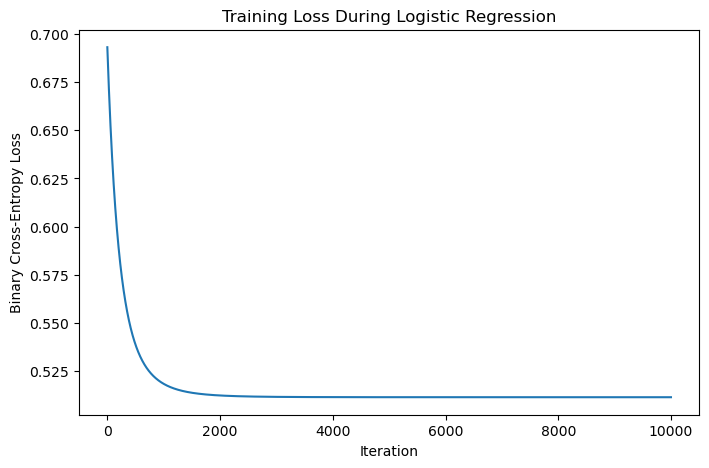

In [36]:
# ============================================
# PLOT TRAINING LOSS
# ============================================

plt.figure(figsize=(8, 5))

plt.plot(model.loss_history)

plt.title("Training Loss During Logistic Regression")
plt.xlabel("Iteration")
plt.ylabel("Binary Cross-Entropy Loss")

plt.show()

## 13. Making Predictions

The trained model produces a probability for each test observation.

A threshold of 0.50 is used to convert probabilities into binary predictions.

For example:

- Probability = 0.80 → Class 1
- Probability = 0.25 → Class 0

In [37]:
# ============================================
# MAKE PREDICTIONS
# ============================================

y_probability = model.predict_proba(X_test_scaled)

y_pred = model.predict(X_test_scaled)

print("First 10 predicted probabilities:")
print(y_probability[:10])

print("\nFirst 10 predicted classes:")
print(y_pred[:10])

First 10 predicted probabilities:
[0.19646688 0.08225379 0.16994625 0.34854821 0.28461093 0.30781281
 0.22913353 0.1940662  0.21770592 0.30343025]

First 10 predicted classes:
[0 0 0 0 0 0 0 0 0 0]


# 14. Model Evaluation

Several evaluation metrics will be used rather than relying only on accuracy.

### Accuracy

Accuracy measures the proportion of all predictions that were correct.

### Precision

Precision measures how many observations predicted as high bestseller potential were actually in the high-potential class.

### Recall

Recall measures how many of the actual high-potential books were correctly identified.

### F1-score

The F1-score combines precision and recall and is useful when both types of errors are important.

### ROC-AUC

ROC-AUC measures how well the model separates the two classes across different probability thresholds.

Using multiple metrics provides a more complete assessment of model performance.

In [38]:
# ============================================
# CALCULATE EVALUATION METRICS
# ============================================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("MODEL PERFORMANCE")
print("----------------------------")
print(f"Accuracy :  {accuracy:.4f}")
print(f"Precision:  {precision:.4f}")
print(f"Recall   :  {recall:.4f}")
print(f"F1-score :  {f1:.4f}")
print(f"ROC-AUC  :  {roc_auc:.4f}")

MODEL PERFORMANCE
----------------------------
Accuracy :  0.7182
Precision:  0.3333
Recall   :  0.1071
F1-score :  0.1622
ROC-AUC  :  0.7378


In [40]:
# ============================================
# CLASSIFICATION REPORT
# ============================================

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Lower Bestseller Potential",
            "High Bestseller Potential"
        ],
        zero_division=0
    )
)

                            precision    recall  f1-score   support

Lower Bestseller Potential       0.75      0.93      0.83        82
 High Bestseller Potential       0.33      0.11      0.16        28

                  accuracy                           0.72       110
                 macro avg       0.54      0.52      0.50       110
              weighted avg       0.65      0.72      0.66       110



In [41]:
# ============================================
# CONFUSION MATRIX
# ============================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[76  6]
 [25  3]]


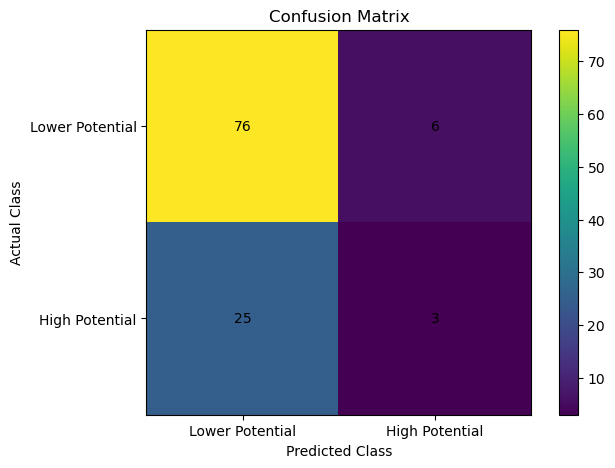

In [42]:
# ============================================
# VISUALISE CONFUSION MATRIX
# ============================================

plt.figure(figsize=(7, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["Lower Potential", "High Potential"]
)

plt.yticks(
    [0, 1],
    ["Lower Potential", "High Potential"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.show()

## 15. ROC Curve

The Receiver Operating Characteristic (ROC) curve shows the relationship between the true-positive rate and false-positive rate at different classification thresholds.

The Area Under the Curve (AUC) provides a single measure of the model's ability to distinguish between the two classes.

An AUC close to 1 indicates strong class separation, while an AUC around 0.5 indicates performance similar to random classification.

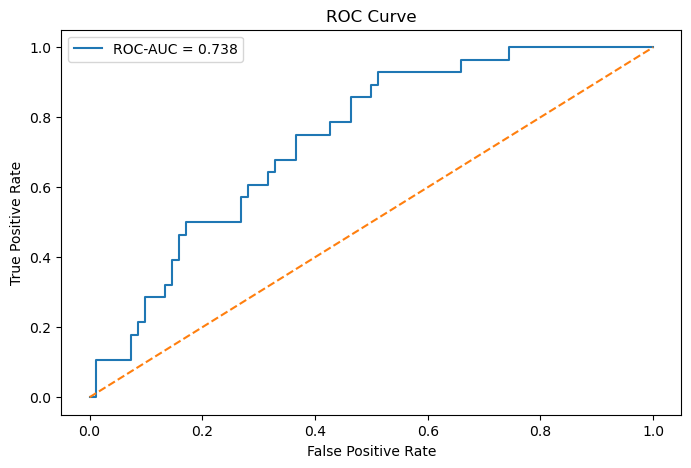

In [43]:
# ============================================
# ROC CURVE
# ============================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()

plt.show()

## 16. Interpreting Model Coefficients

Logistic Regression assigns a coefficient to each feature.

A positive coefficient means that an increase in that feature is associated with an increase in the model's predicted probability of belonging to Class 1, while a negative coefficient indicates the opposite relationship.

Because the features were standardised, the coefficients can be compared more meaningfully in terms of their relative magnitude.

In [44]:
# ============================================
# MODEL COEFFICIENTS
# ============================================

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.weights
})

coefficients["Absolute_Impact"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "Absolute_Impact",
    ascending=False
)

coefficients

,Feature,Coefficient,Absolute_Impact
2,year,0.465855,0.465855
1,price,-0.459434,0.459434
3,genre_Non Fiction,-0.449171,0.449171
0,user_rating,-0.007605,0.007605


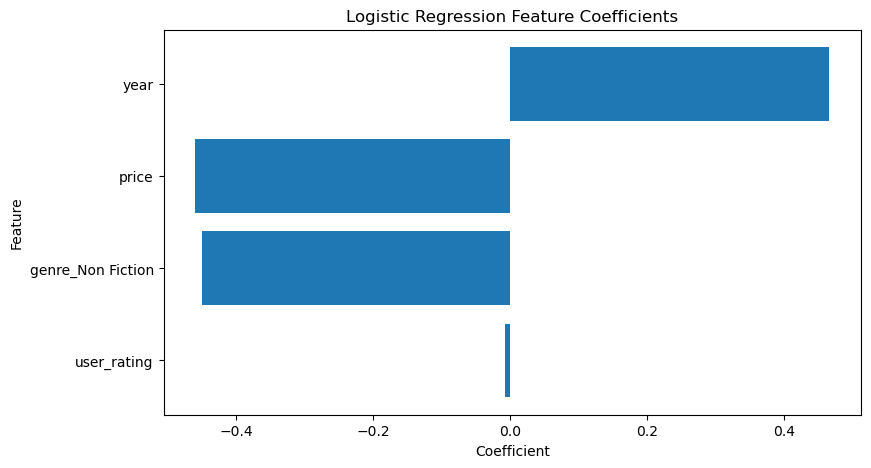

In [45]:
# ============================================
# VISUALISE MODEL COEFFICIENTS
# ============================================

plt.figure(figsize=(9, 5))

plt.barh(
    coefficients["Feature"],
    coefficients["Coefficient"]
)

plt.title("Logistic Regression Feature Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.gca().invert_yaxis()

plt.show()

# 17. Hyperparameter Experimentation

Machine-learning models can produce different results depending on their hyperparameters.

The initial model used:

- Learning rate = 0.01
- Iterations = 10,000

A second model will therefore be trained using a different learning rate and number of iterations.

The performance of the models will then be compared.

This helps determine whether the original parameters were sufficient for convergence and whether changing them improves model performance.

In [47]:
# ============================================
# TRAIN SECOND MODEL
# ============================================

model_2 = LogisticRegressionScratch(
    learning_rate=0.001,
    iterations=20000
)

model_2.fit(
    X_train_scaled,
    y_train.to_numpy()
)

y_probability_2 = model_2.predict_proba(
    X_test_scaled
)

y_pred_2 = model_2.predict(
    X_test_scaled
)

accuracy_2 = accuracy_score(
    y_test,
    y_pred_2
)

precision_2 = precision_score(
    y_test,
    y_pred_2,
    zero_division=0
)

recall_2 = recall_score(
    y_test,
    y_pred_2,
    zero_division=0
)

f1_2 = f1_score(
    y_test,
    y_pred_2,
    zero_division=0
)

roc_auc_2 = roc_auc_score(
    y_test,
    y_probability_2
)

print("SECOND MODEL")
print("----------------------------")
print(f"Accuracy :  {accuracy_2:.4f}")
print(f"Precision:  {precision_2:.4f}")
print(f"Recall   :  {recall_2:.4f}")
print(f"F1-score :  {f1_2:.4f}")
print(f"ROC-AUC  :  {roc_auc_2:.4f}")

SECOND MODEL
----------------------------
Accuracy :  0.7273
Precision:  0.3750
Recall   :  0.1071
F1-score :  0.1667
ROC-AUC  :  0.7400


In [48]:
# ============================================
# COMPARE MODELS
# ============================================

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Model 1": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],

    "Model 2": [
        accuracy_2,
        precision_2,
        recall_2,
        f1_2,
        roc_auc_2
    ]
})

comparison

,Metric,Model 1,Model 2
0,Accuracy,0.718182,0.727273
1,Precision,0.333333,0.375000
2,Recall,0.107143,0.107143
3,F1-score,0.162162,0.166667
4,ROC-AUC,0.737805,0.739983


# 18. Model Comparison

The two Logistic Regression models were trained using different optimisation parameters.

Model 1 used a learning rate of 0.01 and 10,000 iterations.

Model 2 used a learning rate of 0.001 and 20,000 iterations.

The evaluation metrics are compared to determine whether the second configuration improved classification performance.

The preferred model should not be selected based only on accuracy. Precision, recall, F1-score and ROC-AUC should also be considered.

If the differences between the models are small, this suggests that the model is relatively stable with respect to these optimisation parameters.

# 19. Model Comparison

The two Logistic Regression models were trained using different optimisation parameters.

Model 1 used a learning rate of 0.01 and 10,000 iterations.

Model 2 used a learning rate of 0.001 and 20,000 iterations.

The evaluation metrics are compared to determine whether the second configuration improved classification performance.

The preferred model should not be selected based only on accuracy. Precision, recall, F1-score and ROC-AUC should also be considered.

If the differences between the models are small, this suggests that the model is relatively stable with respect to these optimisation parameters.

# 20. Limitations of the Analysis

Several limitations must be considered when interpreting the results.

### 1. Dataset limitation

The dataset consists of books that were already included in Amazon's Top 50 bestselling books. Therefore, the dataset does not represent the complete population of books.

### 2. Constructed target

The classification target was created using the 75th percentile of review counts. Therefore, the target represents high review-based bestseller potential rather than an official bestseller label.

### 3. Review leakage

The number of reviews was excluded from the predictor variables because it was used to construct the target.

### 4. Small dataset

The dataset contains a relatively small number of observations for machine-learning purposes.

### 5. Limited features

The dataset contains only a small number of variables. Other factors such as marketing expenditure, author popularity, publisher, advertising, book release strategy and sales volume could potentially influence bestseller performance.

### 6. Classification interpretation

The model should therefore be interpreted as a demonstration of Logistic Regression classification rather than a production-ready system for predicting actual Amazon bestseller status.

# 21. Conclusion

This project implemented a binary Logistic Regression classification model from scratch using Python.

The analysis began with an evaluation of the Amazon bestselling books dataset, followed by data inspection, cleaning and exploratory analysis.

Several characteristics of the books were investigated, including user rating, price, publication year and genre.

Because the dataset did not contain an explicit binary bestseller outcome, a classification target was created using the 75th percentile of review counts. Books at or above this threshold were classified as having high bestseller potential.

A Logistic Regression algorithm was then implemented from scratch using the sigmoid function, binary cross-entropy loss and gradient descent.

The model was evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix
- ROC Curve

A second model was also trained using different hyperparameters to investigate whether optimisation settings affected model performance.

Overall, the project demonstrates the complete classification workflow, including data preparation, feature selection, model development, evaluation and interpretation.

The main limitation is that the dataset contains only books that were already bestselling, meaning the model should not be interpreted as a true predictor of whether an arbitrary book will become an Amazon bestseller. A stronger future study would combine bestselling and non-bestselling books and use an actual bestseller label.